## This notebook was used to develop and test the script to generate the synthetic scripts.

In [ ]:
import sys

sys.path.append('../')

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from Preprocessing.ng_loader import df_all_cycles, generate_row_script
from Preprocessing.ng_cycles_stats import calculate_cycles
from scipy.stats import qmc, rv_histogram

def inverse_min_max_normalize(data, min_val, max_val):
    """
    Inverse the min-max normalization of the data.

    Parameters:
    ----------
    data (np.ndarray): The normalized data.
    min_val (float): The minimum value used for normalization.
    max_val (float): The maximum value used for normalization.

    Returns:
    -------
    np.ndarray: A numpy array containing the original data.
    """
    return np.array(data) * (max_val - min_val) + min_val

def generate_len_of_cycles(num_samples=1000, time_unit='months', percent_idle=0.13):
    """
    Generate synthetic injection and withdrawal cycles based on the statistics
    of the real cycles.

    Parameters:
    ----------
    num_samples (int): The number of synthetic samples to generate.
    time_unit (str): The unit of time for the duration calculation ('days',
    'weeks' or 'months').

    Returns:
    -------
    pd.DataFrame: A DataFrame containing the synthetic cycles.
    """
    df_all = df_all_cycles('../data/Agsi_data_depleted/', MAXrate=6 *
                           (10**5), time_unit=time_unit, synthetic=True)

    inj_dict, with_dict, idle_dict, site_data = calculate_cycles(df_all)

    inj_cycle_lengths = inj_dict['injection_lengths_normalized']
    with_cycle_lengths = with_dict['withdrawal_lengths_normalized']
    idle_cycle_lengths = idle_dict['idle_lengths_normalized']

    inj_length_hist = rv_histogram(np.histogram(
        inj_cycle_lengths, bins=np.linspace(0, 1, 10)))
    with_length_hist = rv_histogram(np.histogram(
        with_cycle_lengths, bins=np.linspace(0, 1, 10)))
    idle_length_hist = rv_histogram(np.histogram(
        idle_cycle_lengths, bins=5))

    u = qmc.LatinHypercube(d=2, seed=42).random(num_samples)

    idle_samples = int(((num_samples * 2) * percent_idle) / (1 - percent_idle))

    i = qmc.LatinHypercube(d=1, seed=42).random(idle_samples)

    inj_samples = inj_length_hist.ppf(u[:, 0])
    with_samples = with_length_hist.ppf(u[:, 1])
    idle_samples = idle_length_hist.ppf(i[:, 0])

    inj_max = inj_dict['injection_min_max'][1]
    with_max = with_dict['withdrawal_min_max'][1]
    idle_max = idle_dict['idle_min_max'][1]

    inj_min = inj_dict['injection_min_max'][0]
    with_min = with_dict['withdrawal_min_max'][0]
    idle_min = idle_dict['idle_min_max'][0]

    inj_lengths_real = inverse_min_max_normalize(inj_samples, inj_min, inj_max).round().astype(int)
    with_lengths_real = inverse_min_max_normalize(with_samples, with_min, with_max).round().astype(int)
    idle_lengths_real = inverse_min_max_normalize(idle_samples, idle_min, idle_max).round().astype(int)

    print(f"Inj_samples mean: {np.mean(inj_lengths_real)}, std: {np.std(inj_lengths_real)}, median: {np.median(inj_lengths_real)}")
    print(f"With_samples mean: {np.mean(with_lengths_real)}, std: {np.std(with_lengths_real)}, median: {np.median(with_lengths_real)}")
    print(f"Idle_samples mean: {np.mean(idle_lengths_real)}, std: {np.std(idle_lengths_real)}, median: {np.median(idle_lengths_real)}")

    print('Normalized ___________________________')

    print(f"Inj_samples mean: {np.mean(inj_samples)}, std: {np.std(inj_samples)}, median: {np.median(inj_samples)}")
    print(f"With_samples mean: {np.mean(with_samples)}, std: {np.std(with_samples)}, median: {np.median(with_samples)}")
    print(f"Idle_samples mean: {np.mean(idle_samples)}, std: {np.std(idle_samples)}, median: {np.median(idle_samples)}")

    return pd.DataFrame({
        'injection_lengths': inj_samples,
        'withdrawal_lengths': with_samples,
        'injection_lengths_real': inj_lengths_real,
        'withdrawal_lengths_real': with_lengths_real,
    }), pd.DataFrame({
        'idle_lengths': idle_samples,
        'idle_lengths_real': idle_lengths_real
    })




In [ ]:
def row_to_individual_months(row):
    df_indiv = pd.DataFrame()
    df_indiv['months'] = np.arange(1, int(row['injection_lengths_real'] + row['withdrawal_lengths_real'] + row['idle_lengths_real']) + 1)
    df_indiv['cycle_position'] = np.concatenate([
        np.full(int(row['injection_lengths_real']), 'injection'),
        np.full(int(row['withdrawal_lengths_real']), 'withdrawal'),
        np.full(int(row['idle_lengths_real']), 'idle')
    ])
    return df_indiv

def length_to_individual_months(df, idle_df, num_samples, percent_idle=0.13):
    # df['injection_lengths_real'] = df['injection_lengths_real'].round().astype(int)
    # df['withdrawal_lengths_real'] = df['withdrawal_lengths_real'].round().astype(int)
    # df['idle_lengths_real'] = df['idle_lengths_real'].round().astype(int)

    df_indiv = pd.DataFrame()
    count = 0
    site = 1
    idle_idx = 0
    idle_prob = (num_samples * percent_idle) / (1 - percent_idle)
    for idx, row in df.iterrows():
        rand_num1 = np.random.rand() #if idle should be added after injection or after withdrawal
        rand_num2 = np.random.rand() # where idle should be added

        inj_l = max(1, int(round(row['injection_lengths_real'])))
        with_l = max(1, int(round(row['withdrawal_lengths_real'])))

        inj_months = np.arange(1, inj_l + 1)
        with_months = np.arange(1, with_l + 1)

        df_inj = pd.DataFrame({
             'Month': inj_months,
             'Cycle_position_normalized': (inj_months/ inj_l),
             'Phase': np.full(inj_l, 'injection'),
             })

        df_with = pd.DataFrame({
            'Month': with_months,
            'Cycle_position_normalized': (with_months/ with_l),
            'Phase': np.full(with_l, 'withdrawal'),
        })
        if rand_num1 <= idle_prob: # add idle phase
            if idle_idx >= len(idle_df):
                continue
            row = idle_df.iloc[idle_idx]
            idle_l = max(1, int(round(row['idle_lengths_real'])))
            months = np.arange(1, idle_l + 1)
            df_idle = pd.DataFrame({
                    'Month': months,
                    'Cycle_position_normalized': (months/ idle_l),
                    'Phase': np.full(idle_l, 'idle'),
                })
            idle_idx += 1

            count += inj_l + with_l + idle_l
            if rand_num2 < 0.5: # after injection add idle phase
                df_temp = pd.concat([df_inj, df_idle, df_with], ignore_index=True)
            else: # after withdrawal add idle phase
                df_temp = pd.concat([df_inj, df_with, df_idle], ignore_index=True)
        else:
            df_temp = pd.concat([df_inj, df_with], ignore_index=True)
            count += inj_l + with_l


        df_temp['Site'] = np.full(len(df_temp), site)

        if count >= 120:
            count = 0
            site += 1

        df_indiv = pd.concat([df_indiv, df_temp], ignore_index=True)
    df_indiv['Phase_Change'] = (df_indiv.groupby('Site')['Phase'].transform(
        lambda x: x != x.shift()).astype(int))
    df_indiv['Cycle_ID'] = df_indiv['Phase_Change'].cumsum()
    df_indiv['Normalised_cycle_pos_cut'] = pd.cut(
        df_indiv['Cycle_position_normalized'],
        bins=[0.0, 0.33, 0.66, 1.0],
        labels=[0.33, 0.66, 1.0]
    )
    return df_indiv

In [23]:
df, idle_df = generate_len_of_cycles(num_samples=36000, time_unit='months')

df23 = length_to_individual_months(df, idle_df, num_samples=36000, percent_idle=0.13)

df23[df23['Phase'] == 'idle']['Cycle_ID'].nunique()

df23['Site'].max()




Inj_samples mean: 5.079416666666667, std: 2.44041178077025, median: 6.0
With_samples mean: 4.777694444444444, std: 2.0032049919988557, median: 5.0
Idle_samples mean: 2.4137386131251164, std: 1.210870138066204, median: 2.0
Normalized ___________________________
Inj_samples mean: 0.40753514893267573, std: 0.2412656925988787, median: 0.47549397722355435
With_samples mean: 0.41973916962879143, std: 0.2179017466276247, median: 0.46533839626617
Idle_samples mean: 0.2827507189924687, std: 0.2280240526257908, median: 0.20002871314485818


KeyboardInterrupt: 

In [4]:
df23#.to_csv('synthetic_cycles.csv', index=False)

,Month,Cycle_position_normalized,Phase,Site,Phase_Change,Cycle_ID,Normalised_cycle_pos_cut
0,1,1.000000,injection,1,1,1,1.00
1,1,0.250000,idle,1,1,2,0.33
2,2,0.500000,idle,1,0,2,0.66
3,3,0.750000,idle,1,0,2,1.00
4,4,1.000000,idle,1,0,2,1.00
...,...,...,...,...,...,...,...
131583,1,0.500000,withdrawal,1043,1,32273,0.66
131584,2,1.000000,withdrawal,1043,0,32273,1.00
131585,1,0.333333,idle,1043,1,32274,0.66
131586,2,0.666667,idle,1043,0,32274,1.00


In [5]:
vc_with = df23[df23['Phase'] == 'withdrawal']['Normalised_cycle_pos_cut'].value_counts()
vc_with[0.33]

np.int64(10045)

In [6]:
def get_rate_individual(position, phase, time_unit='months'):

    assert phase in ['injection', 'withdrawal'], "Phase must be either 'injection' or 'withdrawal'"
    assert position in [0.33, 0.66, 1.0], "Position must be one of [0.33, 0.66, 1.0]"
    df_all = df_all_cycles('../data/Agsi_data_depleted/', MAXrate=6 *
                           (10**5), time_unit=time_unit, synthetic=True)
    grouped_cycle_months = df_all.groupby(
            ['Normalised_cycle_pos_cut', 'Phase'], observed=True
        )['Normalised_Net_Injection_Withdrawal']
    return grouped_cycle_months.get_group((position, phase)).values


def create_rate_samples(df):
    vc_inj = df[df['Phase'] == 'injection']['Normalised_cycle_pos_cut'].value_counts()
    vc_with = df[df['Phase'] == 'withdrawal']['Normalised_cycle_pos_cut'].value_counts()

    rate_dict ={
    'inj_33': get_rate_individual(0.33, 'injection'),
    'inj_66': get_rate_individual(0.66, 'injection'),
    'inj_100': get_rate_individual(1.0, 'injection'),
    'with_33': get_rate_individual(0.33, 'withdrawal'),
    'with_66': get_rate_individual(0.66, 'withdrawal'),
    'with_100': get_rate_individual(1.0, 'withdrawal')
    }


    LHS_dict = {}
    hist_dict = {}

    for key, values in rate_dict.items():
        position = float(key.split('_')[1])
        pos = position / 100
        phase = key.split('_')[0]
        if phase == 'inj':
            n_samples = vc_inj[pos]
        else:
            n_samples = vc_with[pos]
        LHS_dict[key] = qmc.LatinHypercube(d=1, seed=42).random(n_samples)
        hist_dict[key] = rv_histogram(np.histogram(values, bins=int(np.sqrt(len(values)))))

    samples_dict = {}
    for key, hist in hist_dict.items():
        samples_dict[key] = hist.ppf(LHS_dict[key][:, 0])

    return samples_dict

def add_rate_samples(df):
    samples_dict = create_rate_samples(df)
    df['Normalised_Net_Injection_Withdrawal'] = 0

    for key, samples in samples_dict.items():
        pos = float(key.split('_')[1])
        position = pos / 100
        phase = key.split('_')[0]
        if phase == 'inj':
            df.loc[(df['Phase'] == 'injection') & (df['Normalised_cycle_pos_cut'] == position), 'Normalised_Net_Injection_Withdrawal'] = samples
        else:
            df.loc[(df['Phase'] == 'withdrawal') & (df['Normalised_cycle_pos_cut'] == position), 'Normalised_Net_Injection_Withdrawal'] = samples


    return df

In [7]:
df54 = add_rate_samples(df23)

/tmp/ipykernel_724216/569218328.py:56: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.80776642 0.63557437 0.97311179 ... 0.47189557 0.79353169 0.77652248]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['Phase'] == 'injection') & (df['Normalised_cycle_pos_cut'] == position), 'Normalised_Net_Injection_Withdrawal'] = samples


In [8]:
df54

,Month,Cycle_position_normalized,Phase,Site,Phase_Change,Cycle_ID,Normalised_cycle_pos_cut,Normalised_Net_Injection_Withdrawal
0,1,1.000000,injection,1,1,1,1.00,0.778959
1,1,0.250000,idle,1,1,2,0.33,0.000000
2,2,0.500000,idle,1,0,2,0.66,0.000000
3,3,0.750000,idle,1,0,2,1.00,0.000000
4,4,1.000000,idle,1,0,2,1.00,0.000000
...,...,...,...,...,...,...,...,...
131583,1,0.500000,withdrawal,1043,1,32273,0.66,0.177727
131584,2,1.000000,withdrawal,1043,0,32273,1.00,0.549845
131585,1,0.333333,idle,1043,1,32274,0.66,0.000000
131586,2,0.666667,idle,1043,0,32274,1.00,0.000000


In [34]:
def generate_full_script(n_samples=1000, time_unit='months', percent_idle=0.13):
    """
    Generate a full script of synthetic injection and withdrawal cycles.

    Parameters:
    ----------
    num_samples (int): The number of synthetic samples to generate.
    time_unit (str): The unit of time for the duration calculation ('days',
    'weeks' or 'months').

    Returns:
    -------
    pd.DataFrame: A DataFrame containing the synthetic cycles.
    """
    num_samples = n_samples * 36
    df, idle_df = generate_len_of_cycles(num_samples=num_samples, time_unit=time_unit, percent_idle=percent_idle)
    df_extend_months = length_to_individual_months(df, idle_df, num_samples=num_samples, percent_idle=percent_idle)
    df_rate_added = add_rate_samples(df_extend_months)
    df_rate_added['Row_Script'] = df_rate_added.apply(generate_row_script, axis=1, MAXrate=6*(10**5), time_unit=time_unit, synthetic=True)
    return df_rate_added

In [35]:
df_synthetic = generate_full_script(n_samples=1000, time_unit='months', percent_idle=0.13)

Inj_samples mean: 5.079416666666667, std: 2.44041178077025, median: 6.0
With_samples mean: 4.777694444444444, std: 2.0032049919988557, median: 5.0
Idle_samples mean: 2.4138315672058, std: 1.2110302785804217, median: 2.0
Normalized ___________________________
Inj_samples mean: 0.40753514893267573, std: 0.2412656925988787, median: 0.47549397722355435
With_samples mean: 0.41973916962879143, std: 0.2179017466276247, median: 0.46533839626617
Idle_samples mean: 0.282752181303741, std: 0.2280272273277528, median: 0.1999995133089182


/tmp/ipykernel_724216/569218328.py:56: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.68509703 0.55463691 0.67987533 ... 0.88281015 0.52162872 0.66932292]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['Phase'] == 'injection') & (df['Normalised_cycle_pos_cut'] == position), 'Normalised_Net_Injection_Withdrawal'] = samples


In [36]:
df_synthetic['Phase'].value_counts()

Phase
injection     27100
withdrawal    25698
idle          12984
Name: count, dtype: int64

In [32]:
df_synthetic['Phase'].value_counts()

Phase
injection     54085
withdrawal    51536
idle          25967
Name: count, dtype: int64

In [17]:
df_synthetic.columns

Index(['Month', 'Cycle_position_normalized', 'Phase', 'Site', 'Phase_Change',
       'Cycle_ID', 'Normalised_cycle_pos_cut',
       'Normalised_Net_Injection_Withdrawal', 'Row_Script'],
      dtype='object')

In [18]:
inj_final_cycle_idxs = df_synthetic[df_synthetic['Phase'] == 'injection'].groupby(['Site', 'Cycle_ID'])['Cycle_position_normalized'].idxmax()
with_final_cycle_idxs = df_synthetic[df_synthetic['Phase'] == 'withdrawal'].groupby(['Site', 'Cycle_ID'])['Cycle_position_normalized'].idxmax()

In [28]:
df_synthetic['Phase'].value_counts()

Phase
injection     182859
withdrawal    171997
idle           11356
Name: count, dtype: int64

In [11]:
df_synthetic[(df_synthetic['Site'] == 30) & (df_synthetic['Cycle_ID'] == 910)]

,Month,Cycle_position_normalized,Phase,Site,Phase_Change,Cycle_ID,Normalised_cycle_pos_cut,Normalised_Net_Injection_Withdrawal,Row_Script
3740,1,0.090909,injection,30,1,910,0.33,0.605176,WCONINJE\n WELL3 GAS 1* RATE 363105.7794450887...
3741,2,0.181818,injection,30,0,910,0.33,0.889435,WCONINJE\n WELL3 GAS 1* RATE 533661.0208510719...
3742,3,0.272727,injection,30,0,910,0.33,0.821001,WCONINJE\n WELL3 GAS 1* RATE 492600.65375818 1...
3743,4,0.363636,injection,30,0,910,0.66,0.987958,WCONINJE\n WELL3 GAS 1* RATE 592775.0371897765...
3744,5,0.454545,injection,30,0,910,0.66,0.810474,WCONINJE\n WELL3 GAS 1* RATE 486284.286583143 ...
3745,6,0.545455,injection,30,0,910,0.66,0.637987,WCONINJE\n WELL3 GAS 1* RATE 382792.1501838360...
3746,7,0.636364,injection,30,0,910,0.66,0.630852,WCONINJE\n WELL3 GAS 1* RATE 378511.0999827685...
3747,8,0.727273,injection,30,0,910,1.00,0.712897,WCONINJE\n WELL3 GAS 1* RATE 427737.9520012543...
3748,9,0.818182,injection,30,0,910,1.00,0.839157,WCONINJE\n WELL3 GAS 1* RATE 503494.2392985397...
3749,10,0.909091,injection,30,0,910,1.00,0.628210,WCONINJE\n WELL3 GAS 1* RATE 376925.9057431363...


In [12]:

from Generation_data_scripts.Eclipse_ng_gen import generate_all_scripts



generate_all_scripts(df = df_synthetic, sch_directory_path='../Data_scripts/Synthetic_Schedule_Files2', data_directory_path='../Data_scripts/Synthetic_DATA_Files', time_unit='months')

In [13]:
df_synthetic['Cycle_'].max()

KeyError: 'Cycle_'

In [ ]:
#Testing module works and values are consistent with notebook.

from Generation_data_scripts.synthetic_script import generate_full_script

df_test = generate_full_script(n_samples=1000, time_unit='months', percent_idle=0.13)

generate_all_scripts(df = df_test, sch_directory_path='../Data_scripts/Synthetic_Schedule_Files2', data_directory_path='../Data_scripts/Synthetic_DATA_Files', time_unit='months')

Inj_samples mean: 5.079416666666667, std: 2.44041178077025, median: 6.0
With_samples mean: 4.777694444444444, std: 2.0032049919988557, median: 5.0
Idle_samples mean: 2.4137386131251164, std: 1.210870138066204, median: 2.0
Normalized ___________________________
Inj_samples mean: 0.40753514893267573, std: 0.2412656925988787, median: 0.47549397722355435
With_samples mean: 0.41973916962879143, std: 0.2179017466276247, median: 0.46533839626617
Idle_samples mean: 0.2827507189924687, std: 0.2280240526257908, median: 0.20002871314485818


/home/tlp25/irp-tlp25/Generation_data_scripts/../Generation_data_scripts/synthetic_script.py:259: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.80776642 0.63557437 0.97311179 ... 0.47189557 0.79353169 0.77652248]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[(df['Phase'] == 'injection') &


In [ ]:
df_test['Site'].max()

np.int64(1043)

/home/tlp25/irp-tlp25/Generation_data_scripts/../Preprocessing/ng_cycles_stats.py:325: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_cycle_months = df_all.groupby(


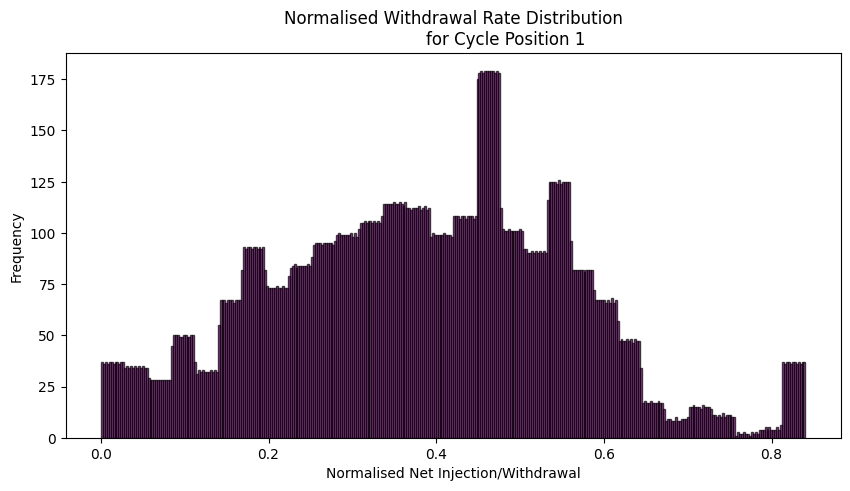

In [ ]:
from Preprocessing.ng_cycles_stats import plot_rate_distribution, calculate_cycles, plot_cycle_histogram

plot_rate_distribution(df_test, cycle='withdrawal', Position=1, All=False, norm=True)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cl = (df_synthetic.groupby('Cycle_ID')
      .agg(Phase=('Phase', 'first'), length=('Month', 'size'))
      .reset_index())
syn_months = cl.loc[cl.Phase == 'injection', 'length'].to_numpy()

# normalize with the SAME min/max the real data used
inj_min, inj_max = inj_dict['injection_min_max']
syn_norm = (syn_months - inj_min) / (inj_max - inj_min)

plt.figure(figsize=(10, 6))
plt.hist(syn_norm, bins=9, edgecolor='black')
plt.title('Synthetic Injection Cycles Distribution')
plt.xlabel('Cycle Length (Months)')
plt.ylabel('Frequency')
plt.show()

NameError: name 'inj_dict' is not defined

In [ ]:
cols = ['Month', 'Cycle_position_normalized', 'Phase', 'Site', 'Phase_Change',
       'Cycle_ID', 'Normalised_cycle_pos_cut',
       'Normalised_Net_Injection_Withdrawal']
df_synthetic[cols].to_csv('synthetic_cycles.csv', index=False)